In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error,r2_score,mean_squared_error,recall_score,precision_score,roc_auc_score,f1_score
from sklearn.linear_model import Lasso,Ridge

In [2]:
df=pd.read_csv(r"C:\Users\ADMIN\Downloads\mediclaim (2).csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
df.shape

(1338, 7)

In [9]:
df.duplicated().sum()

np.int64(1)

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["sex"].unique()

array(['female', 'male'], dtype=object)

In [16]:
df["bmi"].unique().sum()

np.float64(17038.98)

In [17]:
df["smoker"].unique()

array(['yes', 'no'], dtype=object)

In [18]:
df["region"].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

<Axes: >

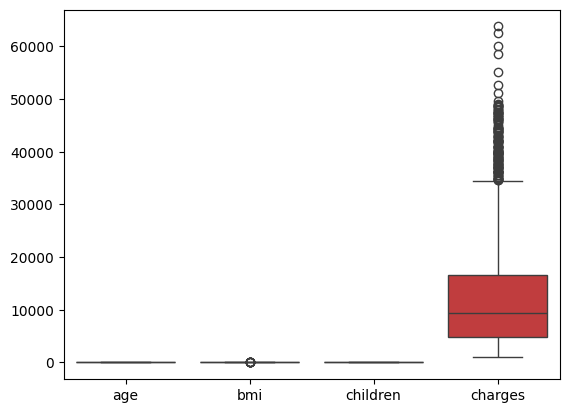

In [21]:
sns.boxplot(df)

In [22]:
x=df.drop("charges",axis=1)

In [23]:
x.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [24]:
y=df["charges"]
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [25]:
x_train,x_teat,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [26]:
x_train,y_train

(      age     sex     bmi  children smoker     region
 1114   23    male  24.510         0     no  northeast
 968    21    male  25.745         2     no  northeast
 599    52  female  37.525         2     no  northwest
 170    63    male  41.470         0     no  southeast
 275    47  female  26.600         2     no  northeast
 ...   ...     ...     ...       ...    ...        ...
 1096   51  female  34.960         2    yes  northeast
 1131   27    male  45.900         2     no  southwest
 1295   20    male  22.000         1     no  southwest
 861    38  female  28.000         3     no  southwest
 1127   35  female  35.860         2     no  southeast
 
 [1069 rows x 6 columns],
 1114     2396.09590
 968      3279.86855
 599     33471.97189
 170     13405.39030
 275      9715.84100
            ...     
 1096    44641.19740
 1131     3693.42800
 1295     1964.78000
 861      7151.09200
 1127     5836.52040
 Name: charges, Length: 1069, dtype: float64)

In [27]:
x_teat,y_test

(      age     sex     bmi  children smoker     region
 900    49    male  22.515         0     no  northeast
 1064   29  female  25.600         4     no  southwest
 1256   51  female  36.385         3     no  northwest
 298    31    male  34.390         3    yes  northwest
 237    31    male  38.390         2     no  southeast
 ...   ...     ...     ...       ...    ...        ...
 534    64    male  40.480         0     no  southeast
 542    63  female  36.300         0     no  southeast
 760    22  female  34.580         2     no  northeast
 1284   61    male  36.300         1    yes  southwest
 1285   47  female  24.320         0     no  northeast
 
 [268 rows x 6 columns],
 900      8688.85885
 1064     5708.86700
 1256    11436.73815
 298     38746.35510
 237      4463.20510
            ...     
 534     13831.11520
 542     13887.20400
 760      3925.75820
 1284    47403.88000
 1285     8534.67180
 Name: charges, Length: 268, dtype: float64)

In [30]:
cl =ColumnTransformer(transformers=[
("tnf1",OneHotEncoder(sparse_output=False),["sex","smoker","region"]),
    ("tnf2",(LinearRegression())
],remainder="passthrough",)

In [33]:
cl.fit_transform(x_train).shape

(1069, 11)

In [36]:
cl.transform(x_teat)

array([[ 0.   ,  1.   ,  1.   , ..., 49.   , 22.515,  0.   ],
       [ 1.   ,  0.   ,  1.   , ..., 29.   , 25.6  ,  4.   ],
       [ 1.   ,  0.   ,  1.   , ..., 51.   , 36.385,  3.   ],
       ...,
       [ 1.   ,  0.   ,  1.   , ..., 22.   , 34.58 ,  2.   ],
       [ 0.   ,  1.   ,  0.   , ..., 61.   , 36.3  ,  1.   ],
       [ 1.   ,  0.   ,  1.   , ..., 47.   , 24.32 ,  0.   ]],
      shape=(268, 11))

In [41]:
pipe=Pipeline([("preprocessor",cl),("model",LinearRegression())])

In [42]:
pipe.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('tnf1', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [44]:
y_pred=pipe.predict(x_teat)
y_pred

array([ 8.14369388e+03,  5.73711568e+03,  1.43693149e+04,  3.17455136e+04,
        8.96238666e+03,  1.31497224e+04,  3.04467607e+04,  1.45328881e+03,
        1.06330184e+04,  1.13189438e+04,  1.03778536e+04,  3.31184377e+04,
        3.10772527e+04,  1.74119253e+04,  1.08016743e+04,  9.52889964e+03,
        4.16103784e+03,  3.17315373e+04,  3.21938875e+03,  5.22992460e+03,
        3.54979004e+03,  3.02837740e+04,  1.48989509e+04,  3.04569093e+04,
        3.11077668e+04,  5.51196081e+03,  3.55030401e+04,  3.65704810e+04,
        1.14123133e+04,  1.42056990e+04,  6.50234029e+03,  1.27246945e+04,
        3.99806590e+02,  1.20883980e+04,  3.96592069e+04,  1.23395540e+04,
        4.74412279e+03,  3.91903157e+03,  3.08606789e+04,  8.95870663e+03,
        7.05389441e+03,  3.01125636e+04,  3.47804324e+04,  1.22916189e+04,
        7.35739310e+03,  3.42060530e+03,  6.21243471e+03,  8.98345200e+03,
        4.26401828e+03,  9.01992870e+03,  6.60149578e+03,  1.20802337e+04,
        3.12447687e+04,  

In [46]:
mean_absolute_error(y_test,y_pred)

4177.045561036348

In [47]:
mean_squared_error(y_test,y_pred)

35478020.67523562

In [48]:
r2_score(y_test,y_pred)

0.8069287081198011

In [50]:
lasso_pipe=Pipeline([("preprocessor",cl),("model",Lasso())])

In [51]:
lasso_pipe.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('tnf1', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [54]:
lasso_pred=pipe.predict(x_teat)
lasso_pred

array([ 8.14369388e+03,  5.73711568e+03,  1.43693149e+04,  3.17455136e+04,
        8.96238666e+03,  1.31497224e+04,  3.04467607e+04,  1.45328881e+03,
        1.06330184e+04,  1.13189438e+04,  1.03778536e+04,  3.31184377e+04,
        3.10772527e+04,  1.74119253e+04,  1.08016743e+04,  9.52889964e+03,
        4.16103784e+03,  3.17315373e+04,  3.21938875e+03,  5.22992460e+03,
        3.54979004e+03,  3.02837740e+04,  1.48989509e+04,  3.04569093e+04,
        3.11077668e+04,  5.51196081e+03,  3.55030401e+04,  3.65704810e+04,
        1.14123133e+04,  1.42056990e+04,  6.50234029e+03,  1.27246945e+04,
        3.99806590e+02,  1.20883980e+04,  3.96592069e+04,  1.23395540e+04,
        4.74412279e+03,  3.91903157e+03,  3.08606789e+04,  8.95870663e+03,
        7.05389441e+03,  3.01125636e+04,  3.47804324e+04,  1.22916189e+04,
        7.35739310e+03,  3.42060530e+03,  6.21243471e+03,  8.98345200e+03,
        4.26401828e+03,  9.01992870e+03,  6.60149578e+03,  1.20802337e+04,
        3.12447687e+04,  

In [55]:
mean_absolute_error(y_test,lasso_pred)

4177.045561036348

In [56]:
mean_squared_error(y_test,lasso_pred)

35478020.67523562

In [58]:
r2_score(y_test,lasso_pred)

0.8069287081198011

In [59]:
ridge_pipe=Pipeline([("preprosesor",cl),("model",Ridge())])

In [60]:
ridge_pipe.fit(x_train,y_train)

,steps,"[('preprosesor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('tnf1', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [62]:
ridge_pred=ridge_pipe.predict(x_teat)
ridge_pred

array([ 8.15939408e+03,  5.74963405e+03,  1.43755111e+04,  3.16896572e+04,
        8.98250377e+03,  1.31690544e+04,  3.03872834e+04,  1.46582137e+03,
        1.06481015e+04,  1.13320624e+04,  1.03868043e+04,  3.30626453e+04,
        3.10227380e+04,  1.74173309e+04,  1.08097181e+04,  9.54427160e+03,
        4.17655134e+03,  3.16834505e+04,  3.23707826e+03,  5.24730945e+03,
        3.56664569e+03,  3.02304433e+04,  1.49121065e+04,  3.04039916e+04,
        3.10461066e+04,  5.52034978e+03,  3.54486174e+04,  3.65150836e+04,
        1.14212358e+04,  1.42188663e+04,  6.51202130e+03,  1.27439053e+04,
        4.24258885e+02,  1.21031130e+04,  3.96019939e+04,  1.23481554e+04,
        4.75662256e+03,  3.93052881e+03,  3.08150572e+04,  8.97552807e+03,
        7.06188358e+03,  3.00561435e+04,  3.47321128e+04,  1.23049259e+04,
        7.36782022e+03,  3.43242582e+03,  6.22052816e+03,  8.99358042e+03,
        4.27377255e+03,  9.04111801e+03,  6.61825606e+03,  1.20914351e+04,
        3.11868605e+04,  

In [63]:
mean_absolute_error(y_test,ridge_pred)

4185.52466687436

In [64]:
mean_squared_error(y_test,ridge_pred)

35566368.051205635

In [65]:
r2_score(y_test,ridge_pred)

0.8064479219404114